# 00. Эталонный разбор: успеваемость студентов (students.csv)

**Дисциплина:** «Управление и аналитика данных на предприятии» · СПбПУ, ИПМЭиТ · Лекция 7

**Профиль:** общий пример для всех профилей — «тренажёр» алгоритма

**Бизнес-вопрос:** Можно ли заранее (по известным характеристикам) выявить студентов, которые рискуют не сдать экзамен по письму, чтобы вовремя предложить им подготовительный курс?

**Данные:** `students.csv` — 1000 студентов, 8 признаков. Источник: открытый учебный датасет курса Stepik «От идеи к MVP» ([оригинал](https://raw.githubusercontent.com/evgpat/stepik_from_idea_to_mvp/main/datasets/students.csv)); копия в репозитории курса.

---
Ноутбук построен по единому сценарию из 10 шагов (см. лекцию 7): *вопрос → загрузка → паспорт данных → очистка → разведка → связи и тренды → постановка ML-задачи → train/test → модель и базовая линия → качество и вывод для бизнеса*. Запуск: «Среда выполнения → Выполнить всё». Данные загружаются по постоянной ссылке с GitHub — ничего загружать вручную не нужно.

> **Что исправлено по сравнению с исходным примером.** (1) замена пропусков сделана без `inplace` в цепочке — в pandas ≥ 2 старый вариант *молча не работает*; (2) в модель включены *все* признаки (категориальные — через one-hot), а не только бинарные; (3) добавлена **базовая линия** — без неё нельзя понять, хороша ли точность; (4) добавлены precision / recall / F1 / ROC-AUC и **интерпретация коэффициентов**; (5) после каждого блока — **вывод**.

## Шаг 1. Бизнес-вопрос и гипотеза

* **Объект** — студент; **целевая переменная** — сдал ли письменный экзамен (балл ≥ 50).
* **Гипотеза H1:** подготовительный курс и баллы по другим предметам связаны с успешной сдачей.
* **Цена ошибки:** пропустить «двоечника» (FN) хуже, чем лишний раз предложить курс (FP) → следим за **recall** класса «не сдал».

In [1]:
# Шаг 0. Подключаем библиотеки (как в базовом примере)
import numpy as np                 # вычисления
import pandas as pd                # таблицы
import seaborn as sns              # графики
import matplotlib.pyplot as plt    # графики

sns.set_theme(style="whitegrid", palette=["#37B34A", "#244128", "#7248A0", "#F39768", "#DA4927"])
pd.set_option("display.max_columns", 30)

## Шаг 2. Загрузка данных по постоянной ссылке

In [2]:
URL = "https://raw.githubusercontent.com/alejanro85/uad-lecture7-ml/main/data/students.csv"
df = pd.read_csv(URL)
df.head()

,gender,parental level of education,lunch,test preparation course,math score,reading score,writing score,class_group
0,female,NaN,standard,none,72.0,72.0,74,group B
1,female,some college,standard,completed,69.0,90.0,88,group C
2,female,master's degree,standard,none,90.0,95.0,93,group B
3,male,associate's degree,free/reduced,none,47.0,57.0,44,group A
4,male,some college,standard,none,76.0,78.0,75,group C


## Шаг 3. Паспорт данных: размер, типы, пропуски

**Строки** — объекты (студенты), **столбцы** — признаки.

In [3]:
print("Размер:", df.shape)
df.info()

Размер: (1000, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       923 non-null    str    
 1   parental level of education  924 non-null    str    
 2   lunch                        1000 non-null   str    
 3   test preparation course      1000 non-null   str    
 4   math score                   952 non-null    float64
 5   reading score                990 non-null    float64
 6   writing score                1000 non-null   int64  
 7   class_group                  1000 non-null   str    
dtypes: float64(2), int64(1), str(5)
memory usage: 62.6 KB


In [4]:
df.describe().round(1)

,math score,reading score,writing score
count,952.0,990.0,1000.0
mean,65.5,69.2,68.1
std,16.2,14.6,15.2
min,-5.0,17.0,10.0
25%,56.0,59.0,57.8
50%,66.0,70.0,69.0
75%,76.0,80.0,79.0
max,100.0,100.0,100.0


In [5]:
df.describe(include="object")

,gender,parental level of education,lunch,test preparation course,class_group
count,923,924,1000,1000,1000
unique,2,6,3,2,5
top,female,associate's degree,standard,none,group C
freq,470,212,630,642,319


**Описание признаков**

| признак | смысл | тип |
|---|---|---|
| gender | пол | категориальный (2) |
| parental level of education | образование родителей | категориальный (6) |
| lunch | тип обеда (standard / free-reduced) — косвенный признак дохода семьи | бинарный |
| test preparation course | проходил ли подготовительный курс | бинарный |
| class_group | учебная группа | категориальный (5) |
| math score, reading score | баллы за математику и чтение | числовой 0–100 |
| writing score | балл за письмо → **основа целевой переменной** | числовой 0–100 |

**Вывод по шагу 3:** 1000 объектов; есть пропуски (math score — 48, gender — 77, образование родителей — 76, reading — 10), отрицательный балл по математике (−5) и опечатка `standart` в lunch. Данные нужно почистить.

## Шаг 4. Очистка: пропуски, ошибки, опечатки

In [6]:
df.isna().sum()

gender                         77
parental level of education    76
lunch                           0
test preparation course         0
math score                     48
reading score                  10
writing score                   0
class_group                     0
dtype: int64

In [7]:
# 4.1 некорректные значения: отрицательный балл -> 0
df["math score"] = df["math score"].clip(lower=0)

# 4.2 пропуски в числовых признаках -> среднее (пропусков < 5%)
for col in ["math score", "reading score"]:
    df[col] = df[col].fillna(df[col].mean())

# 4.3 пропуски в категориях -> отдельная категория "unknown"
for col in ["gender", "parental level of education"]:
    df[col] = df[col].fillna("unknown")

# 4.4 опечатка в категории
df["lunch"] = df["lunch"].replace("standart", "standard")

print(df.isna().sum().sum(), "пропусков осталось")
df["lunch"].value_counts()

0 пропусков осталось


lunch
standard        650
free/reduced    350
Name: count, dtype: int64

**Вывод по шагу 4:** пропусков не осталось, категории приведены к единому написанию. Каждое исправление обосновано: доля пропусков мала, поэтому заполняем, а не удаляем строки.

## Шаг 5. Разведка: распределения (однофакторный анализ)

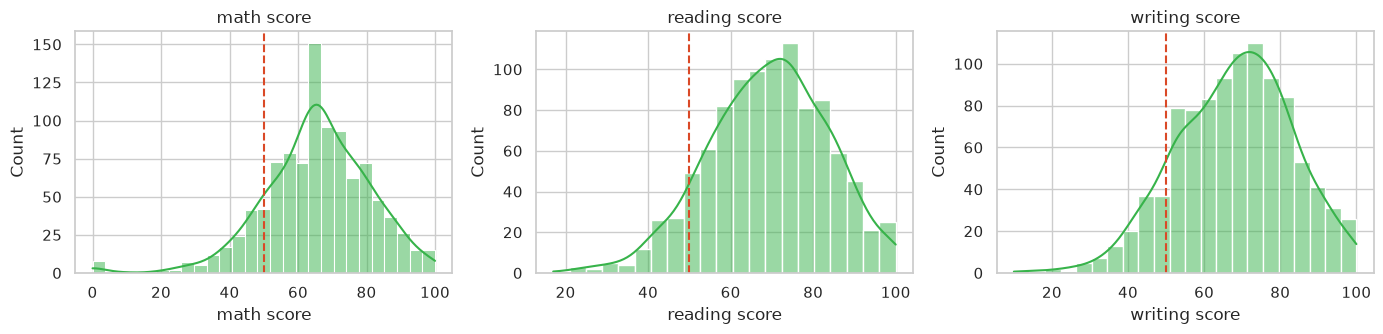

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, col in zip(ax, ["math score", "reading score", "writing score"]):
    sns.histplot(df[col], kde=True, ax=a)
    a.axvline(50, color="#DA4927", ls="--")
    a.set_title(col)
plt.tight_layout(); plt.show()

**Вывод по шагу 5:** распределения баллов близки к нормальному, центр около 66–69. Левее порога 50 (красная линия) — заметное меньшинство: это и есть «группа риска».

## Шаг 6. Связи между признаками и целевой переменной

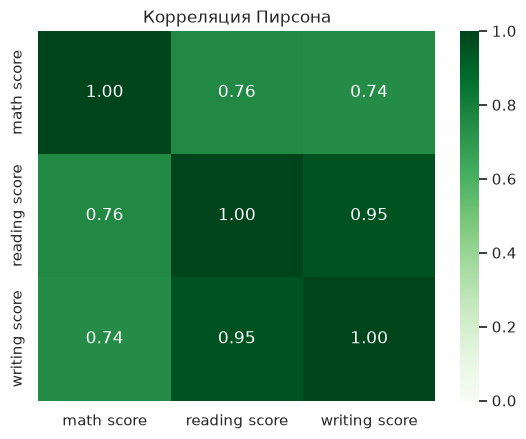

In [9]:
corr = df[["math score", "reading score", "writing score"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1)
plt.title("Корреляция Пирсона"); plt.show()

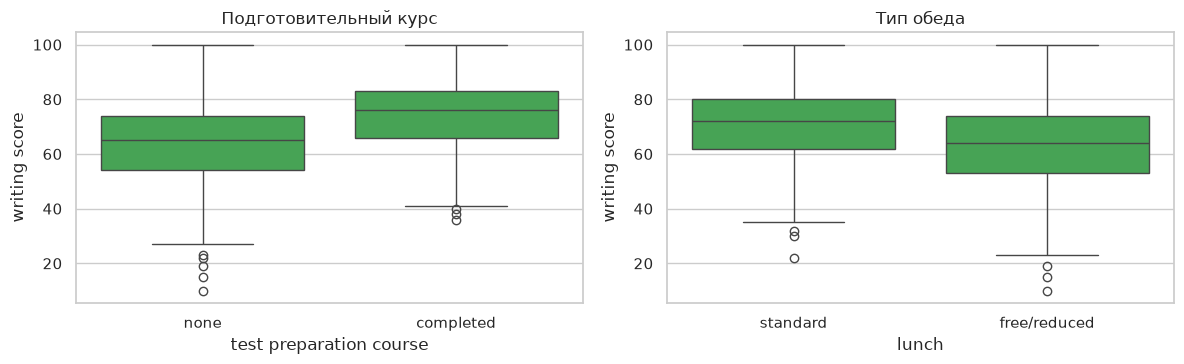

test preparation course
completed    74.4
none         64.5
Name: writing score, dtype: float64

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(data=df, x="test preparation course", y="writing score", ax=ax[0])
sns.boxplot(data=df, x="lunch", y="writing score", ax=ax[1])
ax[0].set_title("Подготовительный курс"); ax[1].set_title("Тип обеда")
plt.tight_layout(); plt.show()
df.groupby("test preparation course")["writing score"].mean().round(1)

**Вывод по шагу 6:** баллы по предметам сильно связаны между собой (ρ ≈ 0.8–0.95). Прошедшие подготовительный курс пишут в среднем заметно лучше; «стандартный» обед (выше доход семьи) — тоже. Гипотеза H1 подтверждается на уровне описательной статистики; проверим её моделью.

## Шаг 7. Постановка ML-задачи: целевая переменная и матрица «объект-признак»

Бинаризация: **1 — сдал (≥ 50), 0 — не сдал**. Задача — **бинарная классификация**. Все признаки должны стать числами: категориальные кодируем one-hot (`get_dummies`).

In [11]:
PASSMARK = 50
y = (df["writing score"] >= PASSMARK).astype(int)   # целевая переменная
X = df.drop(columns=["writing score"])               # признаки (writing score убираем — иначе «подсказка ответа»)
X = pd.get_dummies(X, drop_first=True, dtype=int)    # категории -> 0/1
print("Доля сдавших:", round(y.mean(), 3))
X.head()

Доля сдавших: 0.886


,math score,reading score,gender_male,gender_unknown,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,parental level of education_unknown,lunch_standard,test preparation course_none,class_group_group B,class_group_group C,class_group_group D,class_group_group E
0,72.0,72.0,0,0,0,0,0,0,0,1,1,1,1,0,0,0
1,69.0,90.0,0,0,0,0,0,1,0,0,1,0,0,1,0,0
2,90.0,95.0,0,0,0,0,1,0,0,0,1,1,1,0,0,0
3,47.0,57.0,1,0,0,0,0,0,0,0,0,1,0,0,0,0
4,76.0,78.0,1,0,0,0,0,1,0,0,1,1,0,1,0,0


## Шаг 8. Разбиение на обучающую и тестовую выборки

75% — учимся, 25% — проверяем на «невиданных» данных. `stratify=y` сохраняет долю классов, `random_state=42` — воспроизводимость.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
X_train.shape, X_test.shape

((750, 16), (250, 16))

## Шаг 9. Базовая линия и логистическая регрессия

**Базовая линия** (DummyClassifier) всегда отвечает «сдал». Если модель её не обгоняет — модель бесполезна, какой бы высокой ни казалась точность.

In [13]:
def quality(y_true, y_pred, y_proba=None, name="модель"):
    """Печатает ключевые метрики качества классификатора одной строкой."""
    line = (f"{name:<28} accuracy={accuracy_score(y_true, y_pred):.3f}  "
            f"precision={precision_score(y_true, y_pred, zero_division=0):.3f}  "
            f"recall={recall_score(y_true, y_pred):.3f}  f1={f1_score(y_true, y_pred):.3f}")
    if y_proba is not None:
        line += f"  ROC-AUC={roc_auc_score(y_true, y_proba):.3f}"
    print(line)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
quality(y_test, baseline.predict(X_test), name="Базовая линия")

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]
quality(y_test, pred, proba, name="Логистическая регрессия")

Базовая линия                accuracy=0.884  precision=0.884  recall=1.000  f1=0.938
Логистическая регрессия      accuracy=0.960  precision=0.969  recall=0.986  f1=0.978  ROC-AUC=0.988


## Шаг 10. Оценка качества и интерпретация

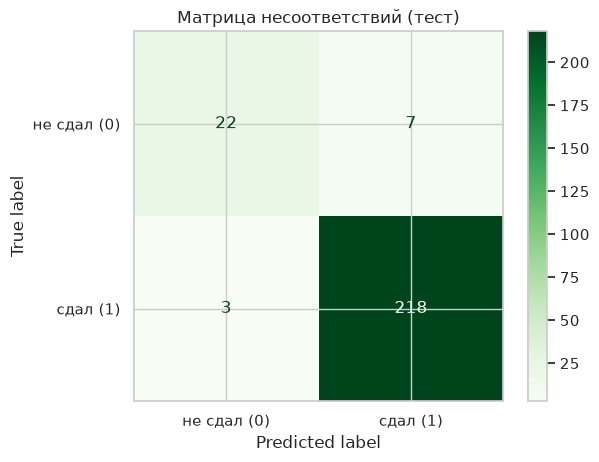

              precision    recall  f1-score   support

     не сдал       0.88      0.76      0.81        29
        сдал       0.97      0.99      0.98       221

    accuracy                           0.96       250
   macro avg       0.92      0.87      0.90       250
weighted avg       0.96      0.96      0.96       250



In [14]:
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["не сдал (0)", "сдал (1)"]).plot(cmap="Greens")
plt.title("Матрица несоответствий (тест)"); plt.show()
print(classification_report(y_test, pred, target_names=["не сдал", "сдал"]))

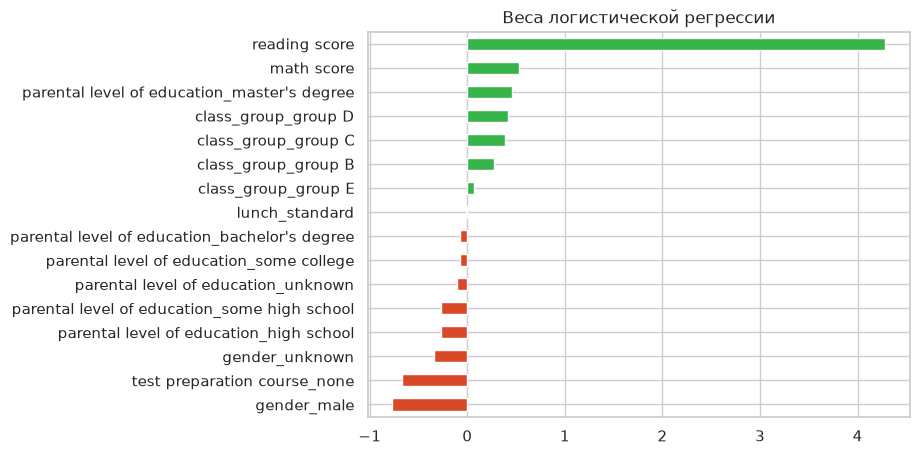

In [15]:
# Какие признаки сильнее всего влияют на прогноз? (признаки стандартизованы -> веса сравнимы)
coef = pd.Series(model[-1].coef_[0], index=X.columns).sort_values()
coef.plot.barh(figsize=(7, 5), color=["#DA4927" if v < 0 else "#37B34A" for v in coef])
plt.title("Веса логистической регрессии"); plt.show()

### Порог решения — управленческий параметр

Модель выдаёт вероятность. По умолчанию «сдаст», если p ≥ 0,5. Если пропуск «двоечника» дорог, поднимем порог: приглашаем на курс всех, у кого p < 0,7.

In [16]:
pred_07 = (proba >= 0.7).astype(int)
quality(y_test, pred_07, proba, name="Порог 0,7")
confusion_matrix(y_test, pred_07)

Порог 0,7                    accuracy=0.948  precision=0.981  recall=0.959  f1=0.970  ROC-AUC=0.988


array([[ 25,   4],
       [  9, 212]])

### Проверка «на честность»: а если оценок по другим предметам нет?

На практике прогноз нужен *до* экзаменов. Уберём math/reading и оставим только анкетные признаки.

In [17]:
X_demo = pd.get_dummies(df[["gender", "parental level of education", "lunch",
                             "test preparation course", "class_group"]], drop_first=True, dtype=int)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(X_demo, y, test_size=0.25, random_state=42, stratify=y)
m_demo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xd_tr, yd_tr)
quality(yd_te, m_demo.predict(Xd_te), m_demo.predict_proba(Xd_te)[:, 1], name="Только анкета")
confusion_matrix(yd_te, m_demo.predict(Xd_te))

Только анкета                accuracy=0.880  precision=0.887  recall=0.991  f1=0.936  ROC-AUC=0.819


array([[  1,  28],
       [  2, 219]])

## Итоговые выводы для «бизнеса» (деканата)

1. **Базовая линия = 88,4%** (доля сдавших). Модель на всех признаках даёт **accuracy = 96%**, ROC-AUC = 0,99 и находит **22 из 29** несдавших (recall класса «не сдал» = 0,76) — она действительно лучше «угадывания».
2. Главные факторы — баллы по чтению и математике; из «управляемых» факторов положительно влияет **подготовительный курс**.
3. **Ловушка accuracy:** модель только по анкете показывает 88% — ровно уровень базовой линии; из 29 несдавших она находит лишь одного. Высокая точность ≠ полезная модель.
4. **Управленческое решение:** промежуточный контроль (аналог math/reading) + автоматическое приглашение на подготовительный курс тем, чья вероятность сдачи < 0,7: так находим **25 из 29** рискующих ценой 9 «лишних» приглашений — порог выбирает менеджер, а не алгоритм.

**Ограничения:** учебный датасет, причинность не доказана (корреляция ≠ причина); для внедрения нужна проверка на данных своего вуза.